In [1]:
import sys, time, json, os
sys.path.insert(0, "..")
from src.spark_utils import get_spark
from pyspark.ml import Pipeline
from pyspark.ml.feature import StringIndexer, OneHotEncoder, VectorAssembler, StandardScaler
from pyspark.ml.regression import LinearRegression, GBTRegressor
from pyspark.ml.evaluation import RegressionEvaluator

spark = get_spark("05-scaling", driver_memory="6g")
df = spark.read.parquet("../data/yellow_2016_03_features.parquet")
print(f"Loaded: {df.count():,} rows")

# Fixed test set across all experiments — only training size varies
train_full, test = df.randomSplit([0.8, 0.2], seed=42)
test.cache()
test.count()  # materialize

Loaded: 7,937,686 rows


1587569

In [2]:
categorical = ["VendorID", "RatecodeID", "pickup_hour", "pickup_dayofweek"]
numeric = [
    "passenger_count", "trip_distance", "fare_amount",
    "extra", "mta_tax", "tolls_amount",
    "trip_duration_min", "avg_speed_mph", "pickup_day",
    "is_weekend", "is_rush_hour", "is_night",
]

def preprocessing():
    indexers = [StringIndexer(inputCol=c, outputCol=f"{c}_idx", handleInvalid="keep") for c in categorical]
    encoders = [OneHotEncoder(inputCol=f"{c}_idx", outputCol=f"{c}_oh") for c in categorical]
    assembler = VectorAssembler(
        inputCols=numeric + [f"{c}_oh" for c in categorical],
        outputCol="features_raw",
    )
    scaler = StandardScaler(inputCol="features_raw", outputCol="features", withMean=False, withStd=True)
    return indexers + encoders + [assembler, scaler]

def lr_pipeline():
    return Pipeline(stages=preprocessing() + [
        LinearRegression(featuresCol="features", labelCol="tip_amount",
                         regParam=0.1, elasticNetParam=0.0, maxIter=50)
    ])

def gbt_pipeline():
    return Pipeline(stages=preprocessing() + [
        GBTRegressor(featuresCol="features", labelCol="tip_amount",
                     maxIter=50, maxDepth=6, stepSize=0.1, seed=42)
    ])

In [3]:
fractions = [0.05, 0.10, 0.25, 0.50, 1.00]   # of train_full
models = {"linear_regression": lr_pipeline, "gbt": gbt_pipeline}

evaluators = {
    m: RegressionEvaluator(labelCol="tip_amount", predictionCol="prediction", metricName=m)
    for m in ["rmse", "mae", "r2"]
}

results = []

for frac in fractions:
    train_subset = train_full.sample(fraction=frac, seed=42).cache()
    n_train = train_subset.count()
    print(f"\n=== fraction={frac}  rows={n_train:,} ===")

    for name, factory in models.items():
        pipe = factory()

        t0 = time.time()
        model = pipe.fit(train_subset)
        train_time = time.time() - t0

        preds = model.transform(test)
        metrics = {m: evaluators[m].evaluate(preds) for m in evaluators}

        row = {
            "model": name,
            "fraction": frac,
            "train_rows": n_train,
            "train_time_sec": round(train_time, 2),
            **{k: round(v, 4) for k, v in metrics.items()},
        }
        results.append(row)
        print(f"  {name:20s} time={train_time:7.1f}s  RMSE={metrics['rmse']:.4f}  R²={metrics['r2']:.4f}")

    train_subset.unpersist()


=== fraction=0.05  rows=316,961 ===
  linear_regression    time=    5.3s  RMSE=1.2965  R²=0.6860
  gbt                  time=   31.4s  RMSE=1.3358  R²=0.6667

=== fraction=0.1  rows=635,226 ===
  linear_regression    time=    3.5s  RMSE=1.2971  R²=0.6857
  gbt                  time=   35.1s  RMSE=1.3198  R²=0.6746

=== fraction=0.25  rows=1,589,184 ===
  linear_regression    time=    5.4s  RMSE=1.2973  R²=0.6856
  gbt                  time=   57.6s  RMSE=1.3108  R²=0.6790

=== fraction=0.5  rows=3,176,464 ===
  linear_regression    time=    9.0s  RMSE=1.2970  R²=0.6858
  gbt                  time=   96.0s  RMSE=1.3077  R²=0.6805

=== fraction=1.0  rows=6,350,117 ===
  linear_regression    time=   16.2s  RMSE=1.2971  R²=0.6857
  gbt                  time=  197.8s  RMSE=1.3029  R²=0.6829


In [4]:
import pandas as pd

scaling_df = pd.DataFrame(results)
scaling_df.to_csv("../results/scaling_results.csv", index=False)
print(scaling_df.to_string(index=False))

            model  fraction  train_rows  train_time_sec   rmse    mae     r2
linear_regression      0.05      316961            5.30 1.2965 0.7047 0.6860
              gbt      0.05      316961           31.44 1.3358 0.7030 0.6667
linear_regression      0.10      635226            3.54 1.2971 0.7055 0.6857
              gbt      0.10      635226           35.08 1.3198 0.7003 0.6746
linear_regression      0.25     1589184            5.35 1.2973 0.7060 0.6856
              gbt      0.25     1589184           57.63 1.3108 0.6993 0.6790
linear_regression      0.50     3176464            9.04 1.2970 0.7054 0.6858
              gbt      0.50     3176464           96.01 1.3077 0.6984 0.6805
linear_regression      1.00     6350117           16.19 1.2971 0.7056 0.6857
              gbt      1.00     6350117          197.80 1.3029 0.6977 0.6829


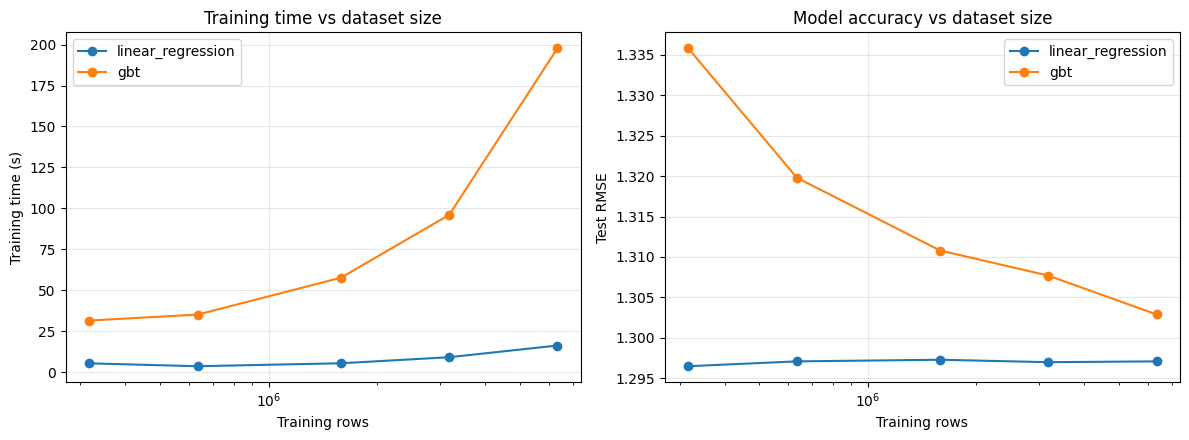

In [5]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

for name in ["linear_regression", "gbt"]:
    sub = scaling_df[scaling_df.model == name]
    axes[0].plot(sub.train_rows, sub.train_time_sec, marker="o", label=name)
    axes[1].plot(sub.train_rows, sub.rmse, marker="o", label=name)

axes[0].set_xlabel("Training rows")
axes[0].set_ylabel("Training time (s)")
axes[0].set_title("Training time vs dataset size")
axes[0].set_xscale("log")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].set_xlabel("Training rows")
axes[1].set_ylabel("Test RMSE")
axes[1].set_title("Model accuracy vs dataset size")
axes[1].set_xscale("log")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("../results/scaling_plot.png", dpi=150, bbox_inches="tight")
plt.show()

In [6]:
spark.stop()